# Laboratory work 3-5
Comparative Analysis of Machine Learning Models Using a Custom Dataset

Target: Priority

Features: CI_Cat, CI_Subcat, Impact, Urgency, Category

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("ITSM_data.csv")

print("Dataset shape:", df.shape)
print("\nFirst five records:")
display(df.head())


Dataset shape: (46606, 25)

First five records:


/tmp/ipykernel_3576/990020199.py:5: DtypeWarning: Columns (7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("ITSM_data.csv")


,CI_Name,CI_Cat,CI_Subcat,WBS,Incident_ID,Status,Impact,Urgency,Priority,number_cnt,...,Reopen_Time,Resolved_Time,Close_Time,Handle_Time_hrs,Closure_Code,No_of_Related_Interactions,Related_Interaction,No_of_Related_Incidents,No_of_Related_Changes,Related_Change
0,SUB000508,subapplication,Web Based Application,WBS000162,IM0000004,Closed,4,4,4.0,0.601292,...,NaN,4/11/2013 13:50,4/11/2013 13:51,"3,87,16,91,111",Other,1.0,SD0000007,2.0,NaN,NaN
1,WBA000124,application,Web Based Application,WBS000088,IM0000005,Closed,3,3,3.0,0.415050,...,2/12/2013 12:31,2/12/2013 12:36,2/12/2013 12:36,"4,35,47,86,389",Software,1.0,SD0000011,1.0,NaN,NaN
2,DTA000024,application,Desktop Application,WBS000092,IM0000006,Closed,NS,3,NaN,0.517551,...,NaN,13-01-2014 15:12,13-01-2014 15:13,"4,84,31,19,444",No error - works as designed,1.0,SD0000017,NaN,NaN,NaN
3,WBA000124,application,Web Based Application,WBS000088,IM0000011,Closed,4,4,4.0,0.642927,...,NaN,14-11-2013 09:31,14-11-2013 09:31,"4,32,18,33,333",Operator error,1.0,SD0000025,NaN,NaN,NaN
4,WBA000124,application,Web Based Application,WBS000088,IM0000012,Closed,4,4,4.0,0.345258,...,NaN,8/11/2013 13:55,8/11/2013 13:55,"3,38,39,03,333",Other,1.0,SD0000029,NaN,NaN,NaN


## Task 1. Describe the dataset

**Dataset Description**

The selected dataset contains IT Service Management (ITSM) incident records. The purpose of the experiment is to compare machine-learning models for predicting incident priority.

Five features are selected: CI_Cat, CI_Subcat, Impact, Urgency, and Category. The target variable is Priority.

This is a multiclass classification task because the model must predict one of several incident priority categories.

In [2]:
features = [
    "CI_Cat",
    "CI_Subcat",
    "Impact",
    "Urgency",
    "Category"
]

target = "Priority"

print("Dataset: ITSM Incident Management")
print("ML Task: Multiclass Classification")
print("Features:", features)
print("Target:", target)

print("\nPriority distribution:")
print(df[target].value_counts(dropna=False))

Dataset: ITSM Incident Management
ML Task: Multiclass Classification
Features: ['CI_Cat', 'CI_Subcat', 'Impact', 'Urgency', 'Category']
Target: Priority

Priority distribution:
Priority
4.0    22717
5.0    16486
3.0     5323
NaN     1380
2.0      697
1.0        3
Name: count, dtype: int64


## Task 2. Prepare the data

In [3]:
print("Missing values:")
print(df[features + [target]].isnull().sum())

print("\nExact duplicate rows:")
print(df.duplicated().sum())

print("\nDuplicate Incident IDs:")
print(df["Incident_ID"].duplicated().sum())

Missing values:
CI_Cat        111
CI_Subcat     111
Impact          0
Urgency         0
Category        0
Priority     1380
dtype: int64

Exact duplicate rows:
0

Duplicate Incident IDs:
0


creating a cleaned dataset

1. Remove records without known priority
2. Remove exact duplicate rows

In [4]:
df_clean = df.dropna(subset=[target]).copy()

df_clean = df_clean.drop_duplicates()

print("Original records:", len(df))
print("Cleaned records:", len(df_clean))


Original records: 46606
Cleaned records: 45226


## Task 3. Train Machine Learning models

In [5]:
print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Duplicate Incident IDs:", df["Incident_ID"].duplicated().sum())

Original records: 46606
Cleaned records: 45226
Duplicate Incident IDs: 0


### Prepare features and target

In [6]:
from sklearn.model_selection import train_test_split

# Use a sample of 5,000 records
df_sample = df_clean.sample(n=5000, random_state=42)

# Features and target from Lab 2
X = df_sample[features]
y = df_sample[target].astype(int)

# Split data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("\nPriority distribution:")
print(y.value_counts().sort_index())

Training records: 4000
Testing records: 1000

Priority distribution:
Priority
2      68
3     578
4    2506
5    1848
Name: count, dtype: int64


### Prepare categorical features

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Convert categorical values to strings
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("to_string", FunctionTransformer(
        lambda x: x.astype(str)
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", categorical_pipeline, features)
    ]
)

print("Preprocessing pipeline v2!")

Preprocessing pipeline v2!


### Define the six models

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),
    "Naive Bayes": MultinomialNB(),
    "SVM": LinearSVC(max_iter=5000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("Models prepared:", len(models))

Models prepared: 6


### Train and evaluate all six models

In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

trained_models = {}
results = []

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predict
    y_pred = pipeline.predict(X_test)

    # Evaluate
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred,
            average="macro",
            zero_division=0
        )
    })

    trained_models[name] = pipeline

    print(f"{name}: completed")

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1-score",
        ascending=False
    ).round(4)
)

Logistic Regression: completed
K-Nearest Neighbors: completed
Naive Bayes: completed
SVM: completed
Decision Tree: completed
Random Forest: completed


,Model,Accuracy,Precision,Recall,F1-score
4,Decision Tree,0.999,0.9995,0.9979,0.9987
0,Logistic Regression,0.999,0.9993,0.9979,0.9986
3,SVM,0.999,0.9993,0.9979,0.9986
2,Naive Bayes,0.999,0.9993,0.9979,0.9986
5,Random Forest,0.999,0.9993,0.9979,0.9986
1,K-Nearest Neighbors,0.994,0.9948,0.9921,0.9934


### Save your comparison table

In [13]:
results_df.to_csv(
    "ITSM_model_comparison.csv",
    index=False
)

print("Model comparison saved!")

Model comparison saved!


## Task 4. Confusion Matrix

Decision Tree Classification Report:
              precision    recall  f1-score   support

           2       1.00      1.00      1.00        11
           3       1.00      0.99      1.00       117
           4       1.00      1.00      1.00       495
           5       1.00      1.00      1.00       377

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



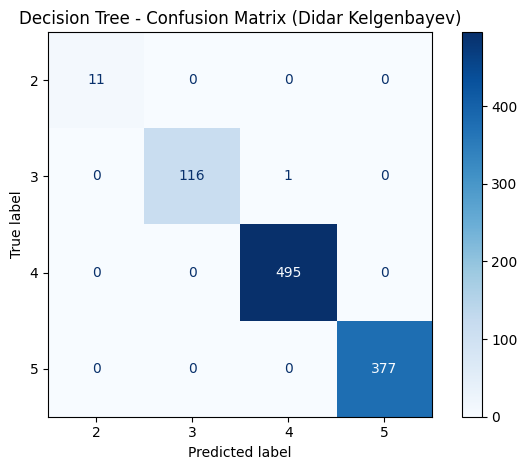

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

best_model = trained_models["Decision Tree"]

y_pred = best_model.predict(X_test)

print("Decision Tree Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    cmap="Blues",
    values_format="d"
)

plt.title("Decision Tree - Confusion Matrix (Didar Kelgenbayev)")
plt.tight_layout()
plt.savefig("ITSM_confusion_matrix.png", dpi=300)
plt.show()

### Task 5. Compare the Models

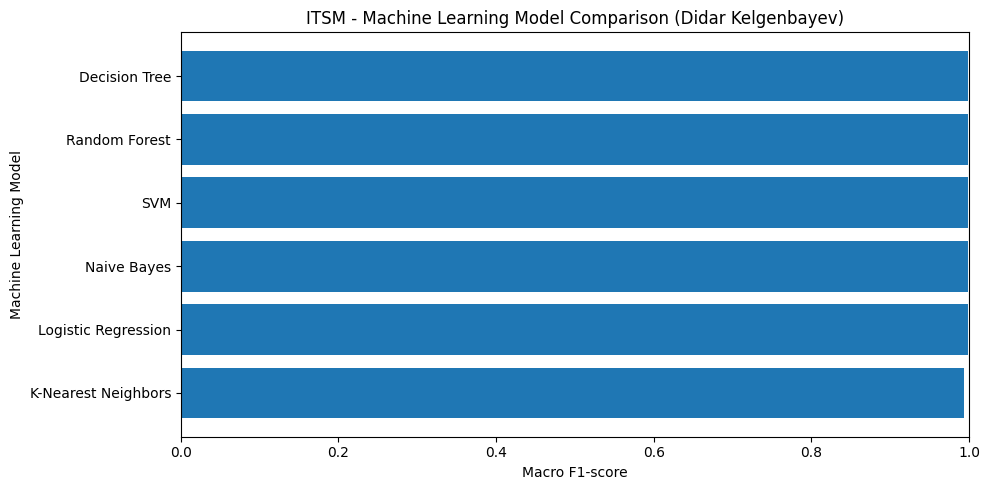

In [17]:
import matplotlib.pyplot as plt

sorted_results = results_df.sort_values("F1-score")

plt.figure(figsize=(10, 5))

plt.barh(
    sorted_results["Model"],
    sorted_results["F1-score"]
)

plt.xlabel("Macro F1-score")
plt.ylabel("Machine Learning Model")
plt.title("ITSM - Machine Learning Model Comparison (Didar Kelgenbayev)")
plt.xlim(0, 1)

plt.tight_layout()
plt.savefig("ITSM_model_comparison.png", dpi=300)
plt.show()

**Model Comparison**

Six classification models were trained and evaluated using the ITSM dataset. Most models achieved 99.9% accuracy, while K-Nearest Neighbors achieved 99.4%.

The Decision Tree Classifier achieved the highest macro F1-score of 0.9987, although its advantage over several other models was very small. Logistic Regression, Naive Bayes, SVM, and Random Forest achieved similar results.

The high performance may be related to the Impact and Urgency features, which can directly influence incident priority. Therefore, further experiments are needed to determine whether the models learn useful incident patterns or mainly reproduce existing priority assignment rules.

## Task 6. Analyze Tree-Based Models

### Visualize the Decision Tree

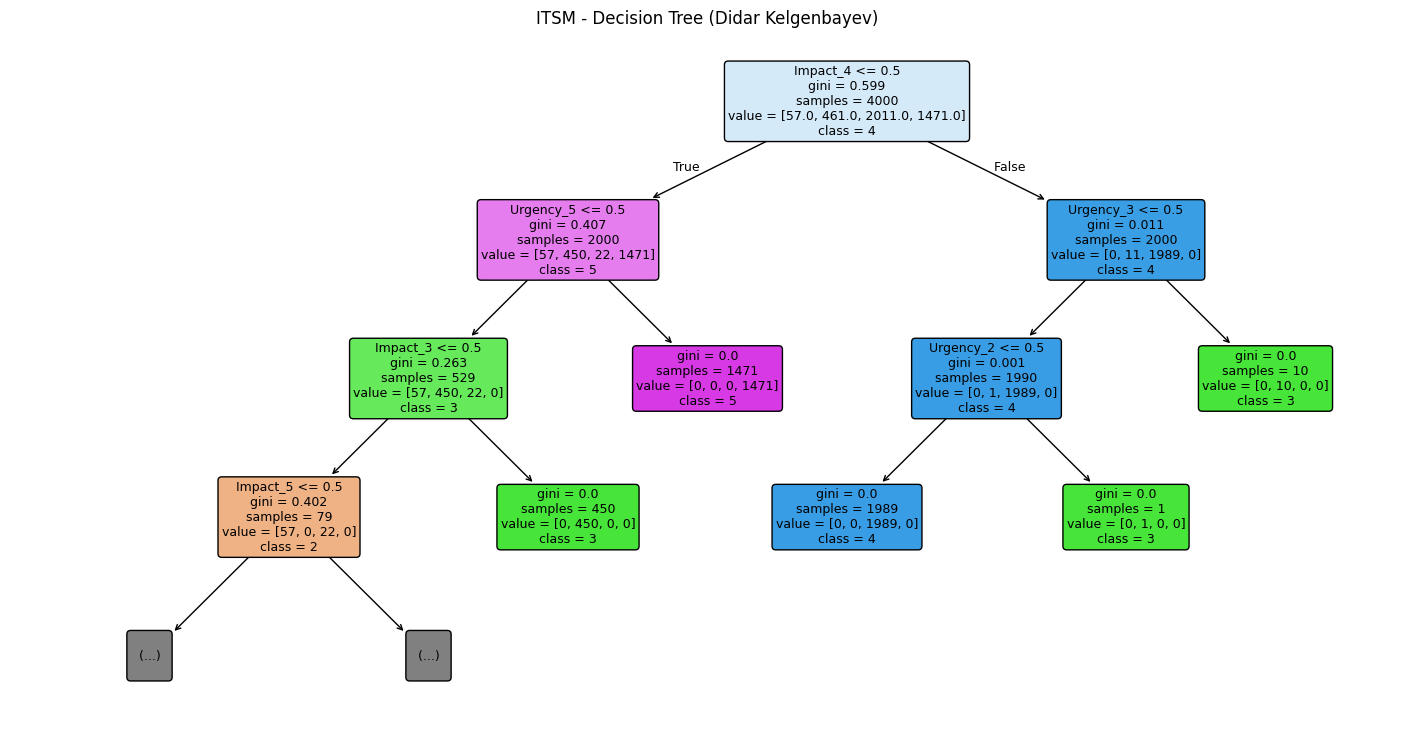

In [23]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

tree_pipeline = trained_models["Decision Tree"]

tree_model = tree_pipeline.named_steps["classifier"]
tree_preprocessor = tree_pipeline.named_steps["preprocessor"]

encoder = (
    tree_preprocessor
    .named_transformers_["cat"]
    .named_steps["encoder"]
)

feature_names = encoder.get_feature_names_out(features)

plt.figure(figsize=(18, 9))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=[str(c) for c in tree_model.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title("ITSM - Decision Tree (Didar Kelgenbayev)")
plt.savefig("ITSM_decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()

### Random Forest feature importance

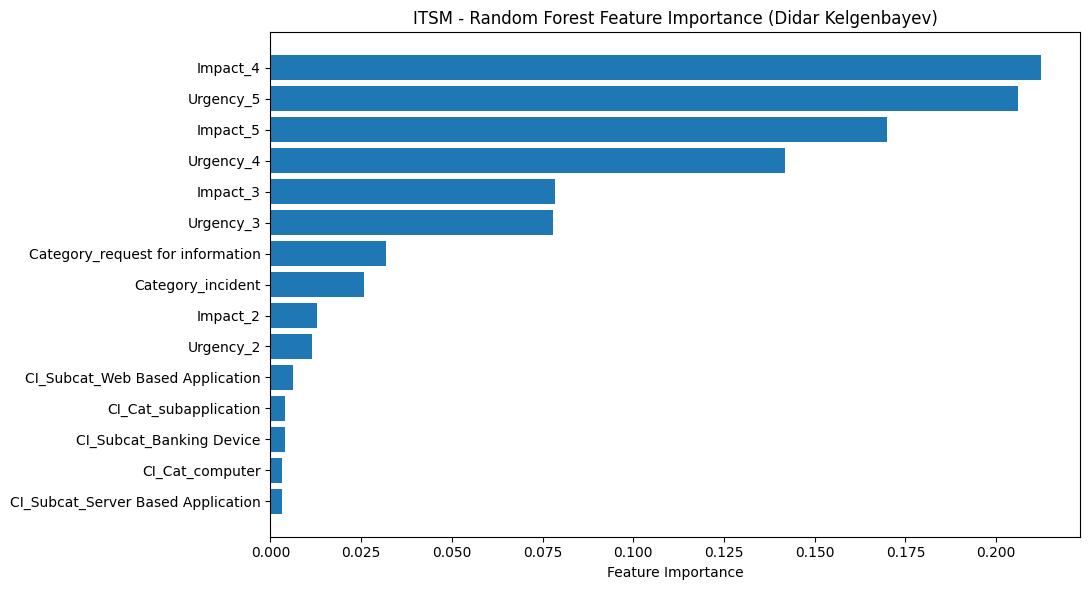

Most important encoded feature:
Feature       Impact_4
Importance    0.212467
Name: 51, dtype: object


In [24]:
import pandas as pd
import matplotlib.pyplot as plt

rf_pipeline = trained_models["Random Forest"]

rf_model = rf_pipeline.named_steps["classifier"]
rf_preprocessor = rf_pipeline.named_steps["preprocessor"]

encoder = (
    rf_preprocessor
    .named_transformers_["cat"]
    .named_steps["encoder"]
)

encoded_names = encoder.get_feature_names_out(features)
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": importances
})

top_features = importance_df.nlargest(15, "Importance")

plt.figure(figsize=(11, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Feature Importance")
plt.title("ITSM - Random Forest Feature Importance (Didar Kelgenbayev)")
plt.tight_layout()
plt.savefig("ITSM_feature_importance.png", dpi=300)
plt.show()

print("Most important encoded feature:")
print(top_features.iloc[0])

**Tree-Based Model Analysis**

The Decision Tree visualization shows how the classifier uses feature values to predict incident priority. The Random Forest feature importance graph shows which encoded features contributed most to the model's decisions.

These visualizations help explain the behavior of tree-based models and identify which incident characteristics are most relevant to their predictions.

## Task 7. Make a New Prediction

In [25]:
# Start with valid feature values from the training data
new_incident = X_train.iloc[[0]].copy()

# Modify a categorical field to create a new observation
new_incident["CI_Subcat"] = "New_Test_Subcategory"

print("New incident:")
display(new_incident)

# Predict incident priority
prediction = best_model.predict(new_incident)

print("Predicted Priority:", prediction[0])

New incident:


,CI_Cat,CI_Subcat,Impact,Urgency,Category
14469,application,New_Test_Subcategory,4,4,incident


Predicted Priority: 4


**Task 7. New Prediction**

A new synthetic incident observation was created using the selected input features. The trained Decision Tree Classifier was used to predict its priority.

**Predicted Priority:** 4

This demonstrates how the trained model can assign a priority class to an observation that was not included in the training dataset.

### Conclusion

In this laboratory work, I trained and compared six machine-learning classification models using the ITSM incident dataset. The dataset was cleaned, categorical features were encoded, and the data was divided into training and testing sets.

The Decision Tree Classifier achieved the highest macro F1-score of 0.9987 and an accuracy of 99.9%. Other models also achieved high results, while K-Nearest Neighbors had slightly lower performance.

I visualized the Decision Tree, examined Random Forest feature importance, and used a trained model to predict the priority of a new synthetic incident.

One limitation is that the dataset has imbalanced priority classes. Also, the high accuracy may be influenced by Impact and Urgency, which can be directly related to incident priority. Further experiments are needed to evaluate the models without these features.

This laboratory work is connected to my diploma research on machine-learning-based incident analysis for AIOps.